In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Simulemos tus datos históricos
data = {
    'Año': [2020, 2021, 2022, 2023],
    'Cajas_Vendidas': [17000, 19500, 21000, 23000]
}

df = pd.DataFrame(data)

# Visualicemos qué tenemos
print("Datos Históricos:")
print(df)

Datos Históricos:
    Año  Cajas_Vendidas
0  2020           17000
1  2021           19500
2  2022           21000
3  2023           23000


In [13]:
# 2. Preprar X (Tiempo) e y (Ventas)
# Sklearn necesita que X sea una matriz 2D (varias filas, 1 columna), por eso usamos [[ ]] o reshape
X = df[['Año']] 
y = df['Cajas_Vendidas']

# 3. Entrenar Regresión Lineal
modelo = LinearRegression()
modelo.fit(X, y)

print(f"\nTendencia aprendida: El modelo dice que vendes {modelo.coef_[0]:.0f} cajas extra por cada año que pasa.")


Tendencia aprendida: El modelo dice que vendes 1950 cajas extra por cada año que pasa.


In [14]:
# 4. Definir los años futuros
anos_futuros = np.array([[2025], [2026]]) # Array 2D

# 5. Predecir
predicciones = modelo.predict(anos_futuros)

# Mostrar resultados
print("\n--- PREDICCIÓN DE VENTAS FUTURAS ---")
for anio, venta in zip(anos_futuros, predicciones):
    print(f"Año {anio[0]}: Se esperan vender {venta:,.0f} cajas")


--- PREDICCIÓN DE VENTAS FUTURAS ---
Año 2025: Se esperan vender 26,950 cajas
Año 2026: Se esperan vender 28,900 cajas


c:\Users\magal\PythonProyects\curso-mpd\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


c:\Users\magal\PythonProyects\curso-mpd\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


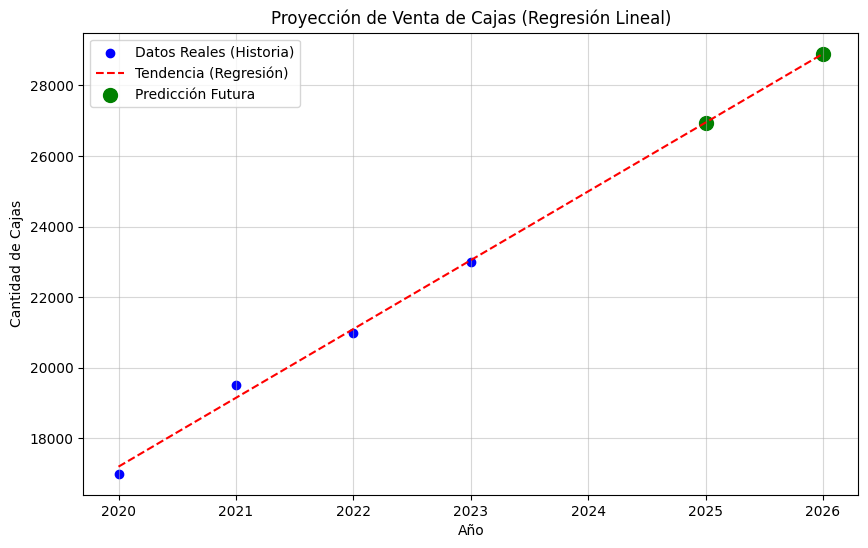

In [15]:
plt.figure(figsize=(10, 6))

# A) Puntos Reales (Historia)
plt.scatter(df['Año'], df['Cajas_Vendidas'], color='blue', label='Datos Reales (Historia)')

# B) Línea de Tendencia (Historia + Futuro)
# Unimos pasado y futuro para dibujar la línea roja completa
todos_los_anos = np.vstack((X, anos_futuros))
prediccion_total = modelo.predict(todos_los_anos)

plt.plot(todos_los_anos, prediccion_total, color='red', linestyle='--', label='Tendencia (Regresión)')

# C) Puntos Futuros (Predicción)
plt.scatter(anos_futuros, predicciones, color='green', s=100, label='Predicción Futura')

plt.title('Proyección de Venta de Cajas (Regresión Lineal)')
plt.xlabel('Año')
plt.ylabel('Cantidad de Cajas')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

In [16]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# 1. Tus Datos (Con Texto)
data = {
    'Año': [2020, 2021, 2022, 2023],
    'Variedad': ['Merlot', 'Cabernet', 'Merlot', 'Cabernet'],
    'Cajas_Vendidas': [17000, 19500, 21000, 23000]
}
df = pd.DataFrame(data)

# 2. TRANSFORMACIÓN: One-Hot Encoding
# pd.get_dummies convierte el texto en columnas numéricas automáticamente
df_procesado = pd.get_dummies(df, columns=['Variedad'])

print("--- Así ve los datos la máquina ---")
print(df_procesado.head())
# Resultado:
#    Año  Ventas  Variedad_Cabernet  Variedad_Merlot
# 0 2020    1000                  0                1
# 1 2020    1500                  1                0

# 3. Entrenar el Modelo
# Ahora X tiene 3 columnas: Año, Es_Cabernet (0/1), Es_Merlot (0/1)
X = df_procesado.drop('Cajas_Vendidas', axis=1)
y = df_procesado['Cajas_Vendidas']

modelo = LinearRegression()
modelo.fit(X, y)

# 4. PREDECIR EL FUTURO
# Queremos saber: ¿Cuánto venderá el MERLOT en 2025?
# Tenemos que armar la pregunta con el mismo formato:
# Año=2025, Variedad_Cabernet=0, Variedad_Merlot=1
futuro = pd.DataFrame({
    'Año': [2025],
    'Variedad_Cabernet': [0], # No es Cabernet
    'Variedad_Merlot': [1]    # Sí es Merlot
})

prediccion = modelo.predict(futuro)
print(f"\nPredicción Venta Merlot 2025: {prediccion[0]:,.0f} cajas")

--- Así ve los datos la máquina ---
    Año  Cajas_Vendidas  Variedad_Cabernet  Variedad_Merlot
0  2020           17000              False             True
1  2021           19500               True            False
2  2022           21000              False             True
3  2023           23000               True            False

Predicción Venta Merlot 2025: 26,500 cajas
